In [10]:
# Cell 1: Import required libraries for portfolio optimization
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

print("Libraries imported successfully for Portfolio Optimization!")

Libraries imported successfully for Portfolio Optimization!


In [13]:
# Cell 2: Download stock data and save locally
import os

# Set a local cache folder to avoid timezone path error
cache_dir = os.path.join(os.getcwd(), '.yf_cache')
os.makedirs(cache_dir, exist_ok=True)
yf.set_tz_cache_location(cache_dir)

tickers = ['AAPL', 'MSFT', 'JPM', '^GSPC']

# Download daily adjusted close prices
data = yf.download(tickers, start='2019-01-01', end='2024-01-01')

# Extract adjusted close prices
if 'Adj Close' in data.columns:
    prices = data['Adj Close']
else:
    prices = data['Close']

# Save locally to csv
prices.to_csv('portfolio_prices.csv')

print("Data downloaded successfully! Shape:", prices.shape)
prices.head()

[*********************100%***********************]  4 of 4 completed

Data downloaded successfully! Shape: (1258, 4)


Ticker,AAPL,JPM,MSFT,^GSPC
Date,,,,
2019-01-02,37.436920,80.074471,94.016136,2510.030029
2019-01-03,33.707924,78.936478,90.557487,2447.889893
2019-01-04,35.146896,81.846542,94.769257,2531.939941
2019-01-07,35.068668,81.903427,94.890106,2549.689941
2019-01-08,35.737183,81.748962,95.578117,2574.409912


In [14]:
# Cell 3: Calculate daily returns and annual covariance matrix
# Load prices from local csv
prices = pd.read_csv('portfolio_prices.csv', index_col='Date', parse_dates=True)

# Calculate daily percentage returns
daily_returns = prices.pct_change().dropna()

# Annualized mean returns and covariance matrix (assuming 252 trading days)
mean_returns = daily_returns.mean() * 252
cov_matrix = daily_returns.cov() * 252

print("Annualized Mean Returns:")
print(mean_returns)
print("\nAnnualized Covariance Matrix:")
print(cov_matrix)


Annualized Mean Returns:
AAPL     0.378031
JPM      0.189012
MSFT     0.320295
^GSPC    0.151584
dtype: float64

Annualized Covariance Matrix:
           AAPL       JPM      MSFT     ^GSPC
AAPL   0.103907  0.046776  0.074562  0.055273
JPM    0.046776  0.101746  0.043779  0.049954
MSFT   0.074562  0.043779  0.092969  0.053750
^GSPC  0.055273  0.049954  0.053750  0.045469


Optimal Portfolio Weights:
AAPL: 0.7408
JPM: 0.0138
MSFT: 0.2432
^GSPC: 0.0022

Expected Annual Return: 0.3609
Expected Annual Volatility: 0.3015
Sharpe Ratio: 1.1970


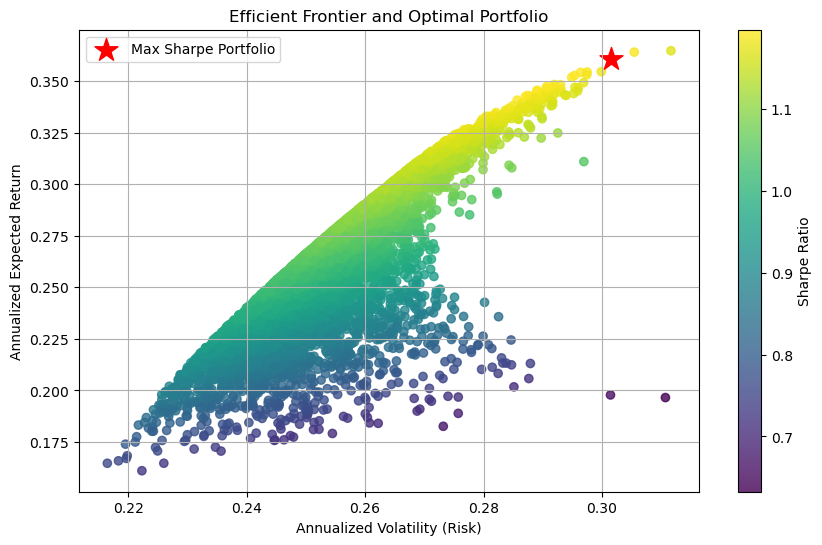

In [15]:
# Cell 4: Monte Carlo simulation for portfolio optimization

num_portfolios = 10000
all_weights = np.zeros((num_portfolios, len(prices.columns)))
portfolio_returns = np.zeros(num_portfolios)
portfolio_volatility = np.zeros(num_portfolios)
portfolio_sharpe = np.zeros(num_portfolios)

np.random.seed(42)

for i in range(num_portfolios):
    weights = np.random.random(len(prices.columns))
    weights /= np.sum(weights)
    all_weights[i, :] = weights
    
    # Expected portfolio return and volatility
    portfolio_returns[i] = np.sum(weights * mean_returns)
    portfolio_volatility[i] = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
    
    # Sharpe ratio (assuming risk-free rate = 0)
    portfolio_sharpe[i] = portfolio_returns[i] / portfolio_volatility[i]

# Find the optimal portfolio with max Sharpe ratio
max_sharpe_idx = np.argmax(portfolio_sharpe)
opt_weights = all_weights[max_sharpe_idx, :]

print("Optimal Portfolio Weights:")
for ticker, weight in zip(prices.columns, opt_weights):
    print(f"{ticker}: {weight:.4f}")

print(f"\nExpected Annual Return: {portfolio_returns[max_sharpe_idx]:.4f}")
print(f"Expected Annual Volatility: {portfolio_volatility[max_sharpe_idx]:.4f}")
print(f"Sharpe Ratio: {portfolio_sharpe[max_sharpe_idx]:.4f}")

# Plot Efficient Frontier
plt.figure(figsize=(10, 6))
plt.scatter(portfolio_volatility, portfolio_returns, c=portfolio_sharpe, cmap='viridis', marker='o', alpha=0.8)
plt.colorbar(label='Sharpe Ratio')
plt.scatter(portfolio_volatility[max_sharpe_idx], portfolio_returns[max_sharpe_idx], color='red', marker='*', s=300, label='Max Sharpe Portfolio')
plt.title('Efficient Frontier and Optimal Portfolio')
plt.xlabel('Annualized Volatility (Risk)')
plt.ylabel('Annualized Expected Return')
plt.legend()
plt.grid(True)
plt.show()


In [16]:
# Cell 5: Downside risk metrics (VaR and Maximum Drawdown)
# Daily returns of the optimal portfolio
port_daily_returns = daily_returns.dot(opt_weights)

# 1. Historical Value at Risk (VaR 95%)
var_95 = np.percentile(port_daily_returns, 5)

# 2. Maximum Drawdown (MDD)
cumulative_returns = (1 + port_daily_returns).cumprod()
peak = cumulative_returns.cummax()
drawdown = (cumulative_returns - peak) / peak
max_drawdown = drawdown.min()

print(f"Daily Value at Risk (VaR 95%): {var_95*100:.2f}%")
print(f"Maximum Drawdown (MDD): {max_drawdown*100:.2f}%")

Daily Value at Risk (VaR 95%): -2.85%
Maximum Drawdown (MDD): -30.83%
